In [1]:
import pymongo as pm
import pandas as pd
from datetime import datetime, timezone
import matplotlib.pyplot as plt
import numpy as np

client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)

In [2]:
db= client['carsharing']
pb_coll = db['PermanentBookings']
ap_coll = db['ActiveParkings']
ab_coll = db['ActiveParkings']
pp_coll = db['PermanentParkings']

In [3]:
start = int(datetime(2017, 11, 1, tzinfo=timezone.utc).timestamp())
end   = int(datetime(2018, 2, 1, tzinfo=timezone.utc).timestamp())
    
cities = ["Torino","Columbus","Frankfurt"]

In [4]:
def load_wtime(coll, city,PT=False):
    
    if PT : 
        pipe = [
            {"$match": {"city": city, "init_time": {"$gte": start, "$lt": end},"public_transport.duration": {"$ne": -1},
        "public_transport.distance": {"$ne": -1}
                       }},
            {"$project": {"_id": 0, 
                          "init_time": 1,
                          "duration": {"$subtract": ["$final_time", "$init_time"]},
                          "day":      {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                            "week":     {"$isoWeek": "$init_date"},
                            "iso_year": {"$isoWeekYear": "$init_date"},
                            "dow":      {"$isoDayOfWeek": "$init_date"},
                            "hour":     {"$hour": "$init_date"},
                          "pt_duration": "$public_transport.duration",
                          "pt_distance": "$public_transport.distance"
                         }}           
        ]
    else : 
        pipe = [
                {"$match": {"city": city, "init_time": {"$gte": start, "$lt": end},
                           }},
                {"$project": {"_id": 0, 
                              "init_time": 1,
                              "duration": {"$subtract": ["$final_time", "$init_time"]},
                              "day":      {"$dateToString": {"date": "$init_date", "format": "%Y-%m-%d"}},
                                "week":     {"$isoWeek": "$init_date"},
                                "iso_year": {"$isoWeekYear": "$init_date"},
                                "dow":      {"$isoDayOfWeek": "$init_date"},
                                "hour":     {"$hour": "$init_date"},
                              "pt_duration": "$public_transport.duration",
                              "pt_distance": "$public_transport.distance"
                             }}           
            ]
        
    df = pd.DataFrame(db[coll].aggregate(pipe, allowDiskUse=True))
    df["duration_min"] = df["duration"]/60
    if PT:
        df["pt_duration_min"] = df["pt_duration"]/60
    return df

In [5]:
bookings = {c: load_wtime("PermanentBookings", c) for c in cities}
parkings = {c: load_wtime("PermanentParkings", c) for c in cities}

In [6]:
def best_zone(x, q=0.9, log=True,min_duration=1.0):
    """
    Zone la plus dense : le plus petit intervalle [a, b] qui contient une fraction q
    des échantillons (sur la ECDF : F(b) - F(a) = q).
    log=True : la largeur est mesurée en log(durée), adapté aux durées très étalées
               -> on enlève à la fois les durées très courtes et la longue traîne.
               Les durées <= 0 (invalides) sont retirées avant le calcul.
    """
    x = np.sort(np.asarray(x, dtype=float))
    x = x[x >= min_duration]

    n = len(x)
    if n == 0:
        return np.nan, np.nan

    k = int(np.ceil(q * n))
    t = np.log(x) if log else x

    # Fenêtre glissante de k points
    widths = t[k - 1 :] - t[: n - k + 1]
    i = np.argmin(widths)

    return x[i], x[i + k - 1]


def keep_best_zone(df, q=0.9, col="duration_min", log=True):
    """Garde uniquement les lignes dont la durée est dans la zone la plus dense."""
    a, b = best_zone(df[col].values, q, log)
    return df[df[col].between(a, b)].copy(), (a, b)


Q = 0.90   # fraction de la ECDF à conserver

raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in cities:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])

bookings_f = filtered["bookings"]
parkings_f = filtered["parkings"]

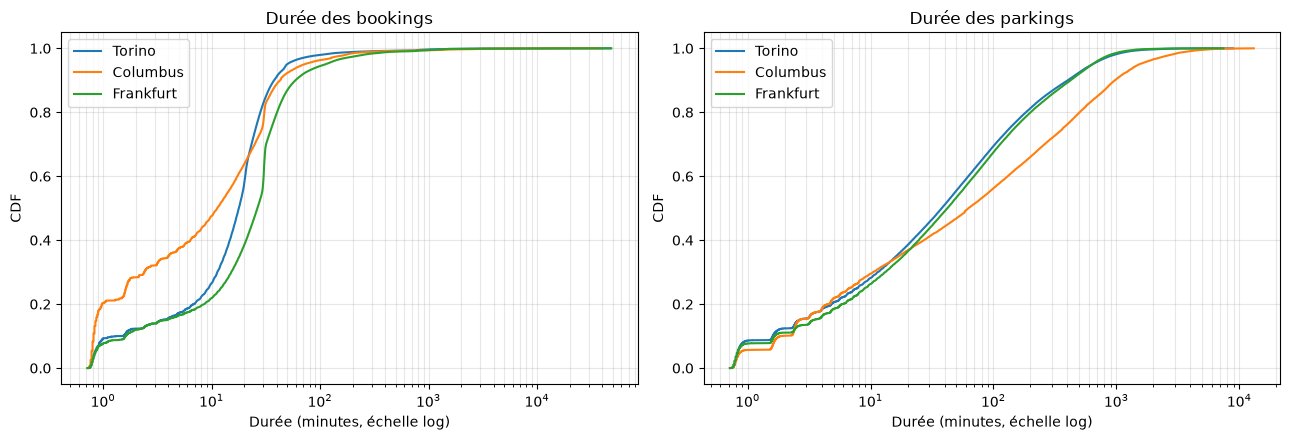

In [7]:
def plot_cdf(data_dict, title, ax):
    for city, df in data_dict.items():
        x = np.sort(df["duration_min"].values)
        x = x[x > 0]                                  # nécessaire pour l'axe log
        y = np.arange(1, len(x)+1) / len(x)
        ax.plot(x, y, label=city)
    ax.set_xscale("log")
    ax.set_xlabel("Durée (minutes, échelle log)")
    ax.set_ylabel("CDF")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_cdf(bookings, "Durée des bookings", axes[0])
plot_cdf(parkings, "Durée des parkings", axes[1])
plt.tight_layout(); plt.show()

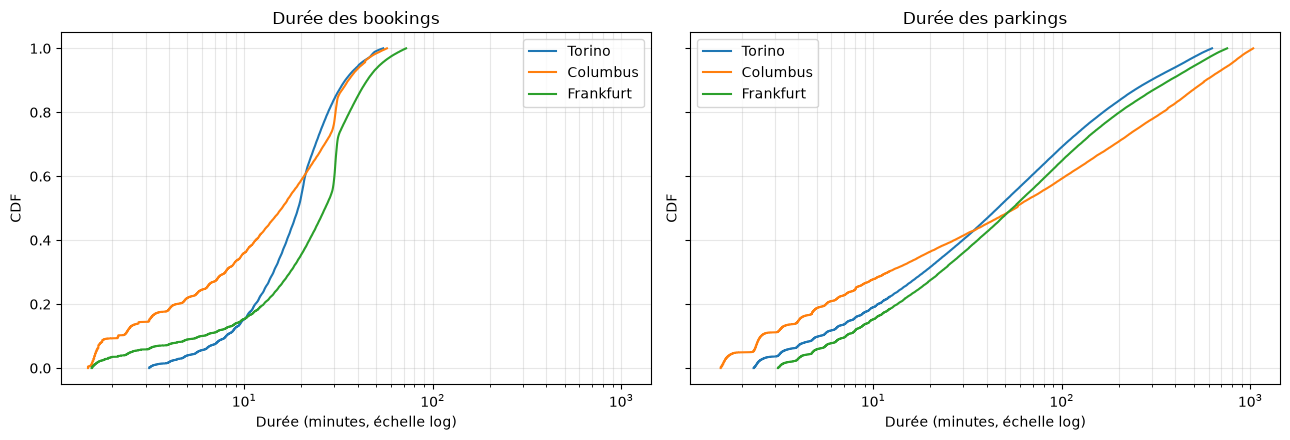

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey= True)

plot_cdf(bookings_f, "Durée des bookings", axes[0])
plot_cdf(parkings_f, "Durée des parkings", axes[1])

plt.tight_layout()
plt.show()

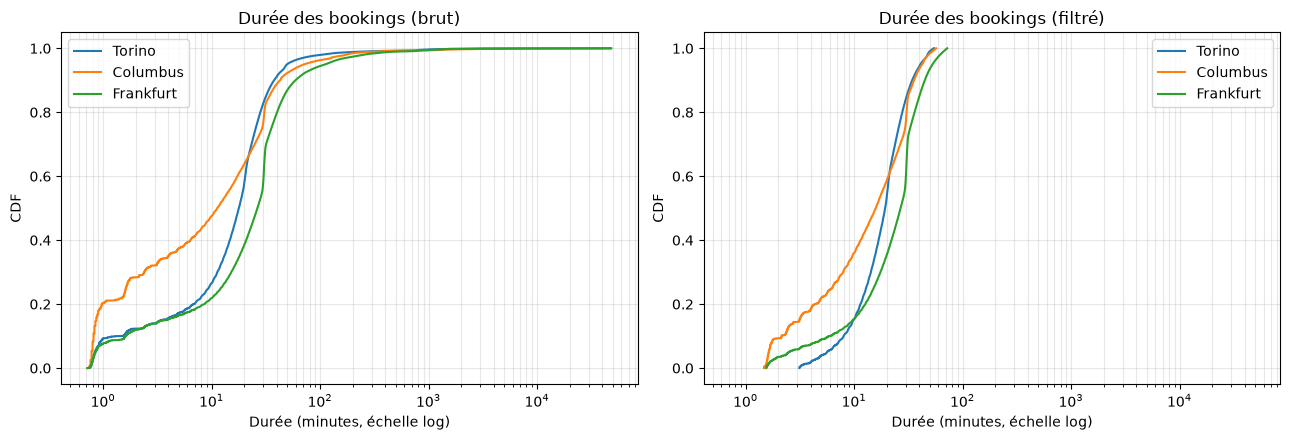

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)

plot_cdf(bookings, "Durée des bookings (brut)", axes[0])

plot_cdf(bookings_f, "Durée des bookings (filtré)", axes[1])

plt.tight_layout()
plt.show()

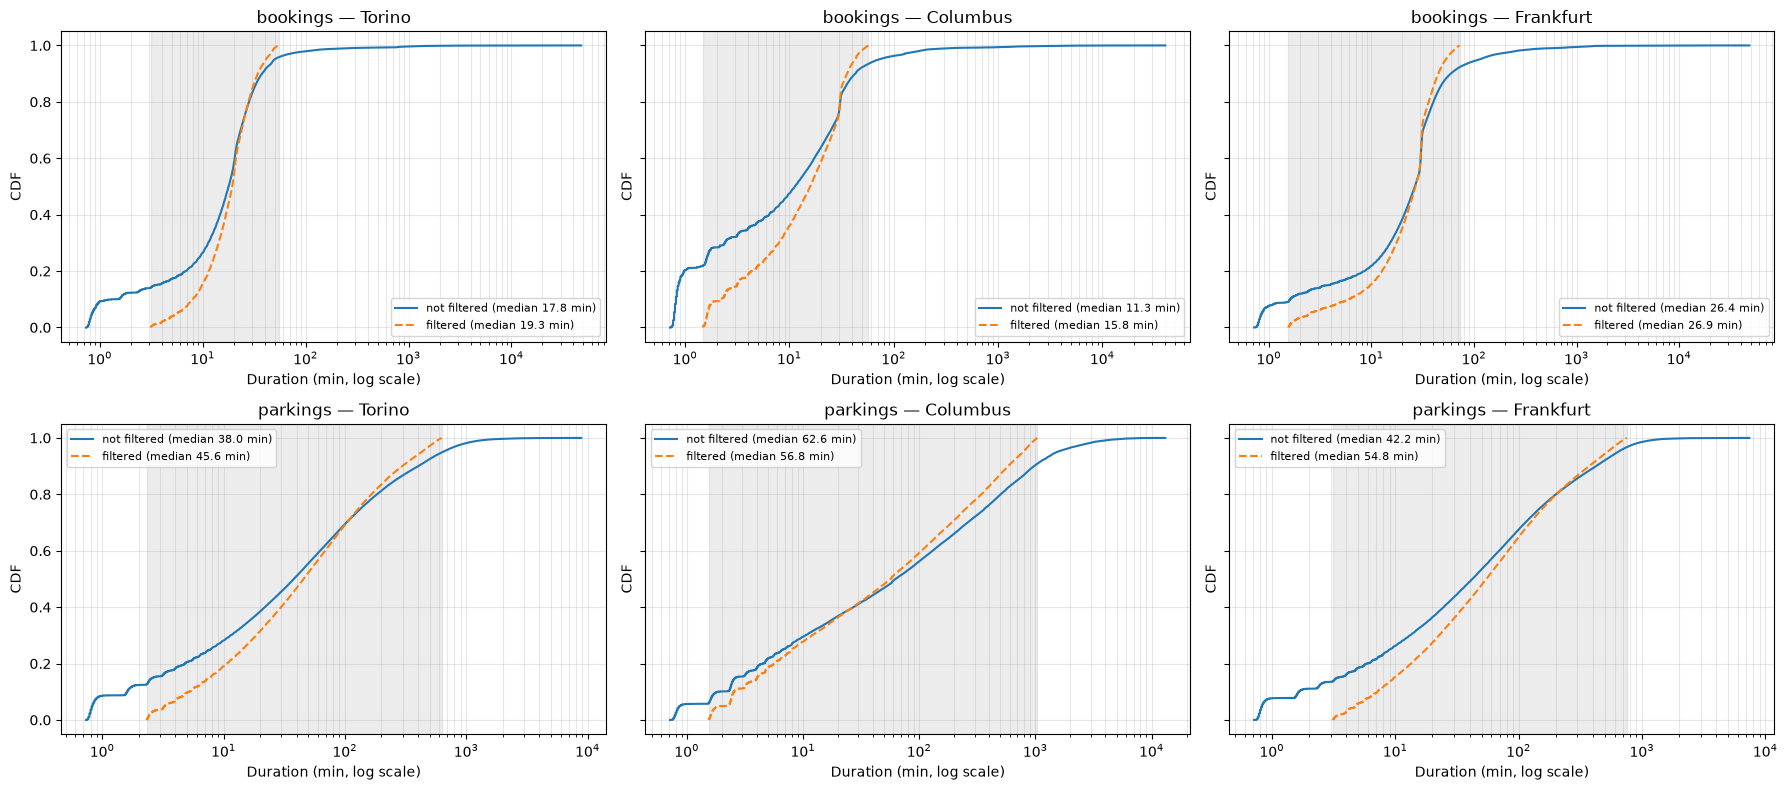

In [23]:

raw = {"bookings": bookings, "parkings": parkings}
filtered = {kind: {} for kind in raw}
zones = {}
for kind, data in raw.items():
    for c in cities:
        filtered[kind][c], zones[(kind, c)] = keep_best_zone(data[c], Q)
        a, b = zones[(kind, c)]
        n0, n1 = len(data[c]), len(filtered[kind][c])

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        for df, style, lab in [(raw[kind][c], "-", "not filtered"), (filtered[kind][c], "--", "filtered")]:
            x = np.sort(df["duration_min"].to_numpy())
            x = x[x > 0]
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                    label=f"{lab} (median {np.median(x):.1f} min)")
        ax.axvspan(*zones[(kind, c)], color="grey", alpha=0.15)
        ax.set_xscale("log")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Duration (min, log scale)")
        ax.set_ylabel("CDF")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Q4 – Utilisation du système et CDF après filtrage
On réutilise `raw`, `filtered` et `zones` calculés plus haut (zone la plus dense, 90 % de la ECDF).

In [9]:
# Occupation horaire : nombre de voitures réservées / garées dans chaque créneau d'1h.
# Même définition que la V1 de TP1.ipynb (un événement compte dans chaque heure qu'il touche),
# mais vectorisée (bincount + cumsum) : instantané au lieu d'une boucle sur ~2200 heures.

TZ = {"Torino": "Europe/Rome", "Columbus": "America/New_York", "Frankfurt": "Europe/Berlin"}
N_HOURS = (end - start) // 3600

def hourly_occupancy(df):
    d = df[df["duration"] > 0]
    t0 = d["init_time"].to_numpy(dtype=np.int64)
    t1 = t0 + d["duration"].to_numpy(dtype=np.int64)
    s = np.clip((t0 - start) // 3600, 0, N_HOURS)        # premier créneau touché
    e = np.clip(-((start - t1) // 3600), 0, N_HOURS)     # créneau de fin, exclu (= arrondi supérieur)
    diff = np.bincount(s, minlength=N_HOURS + 1) - np.bincount(e, minlength=N_HOURS + 1)
    idx = pd.date_range(pd.Timestamp(start, unit="s", tz="UTC"), periods=N_HOURS, freq="h")
    return pd.Series(np.cumsum(diff)[:N_HOURS], index=idx)

def hour_of_day_profile(occ, city):
    """Moyenne de l'occupation pour chaque heure locale (0-23)."""
    local = occ.tz_convert(TZ[city])
    return local.groupby(local.index.hour).mean()

occ_raw = {k: {c: hourly_occupancy(raw[k][c]) for c in cities} for k in raw}
occ_f   = {k: {c: hourly_occupancy(filtered[k][c]) for c in cities} for k in raw}

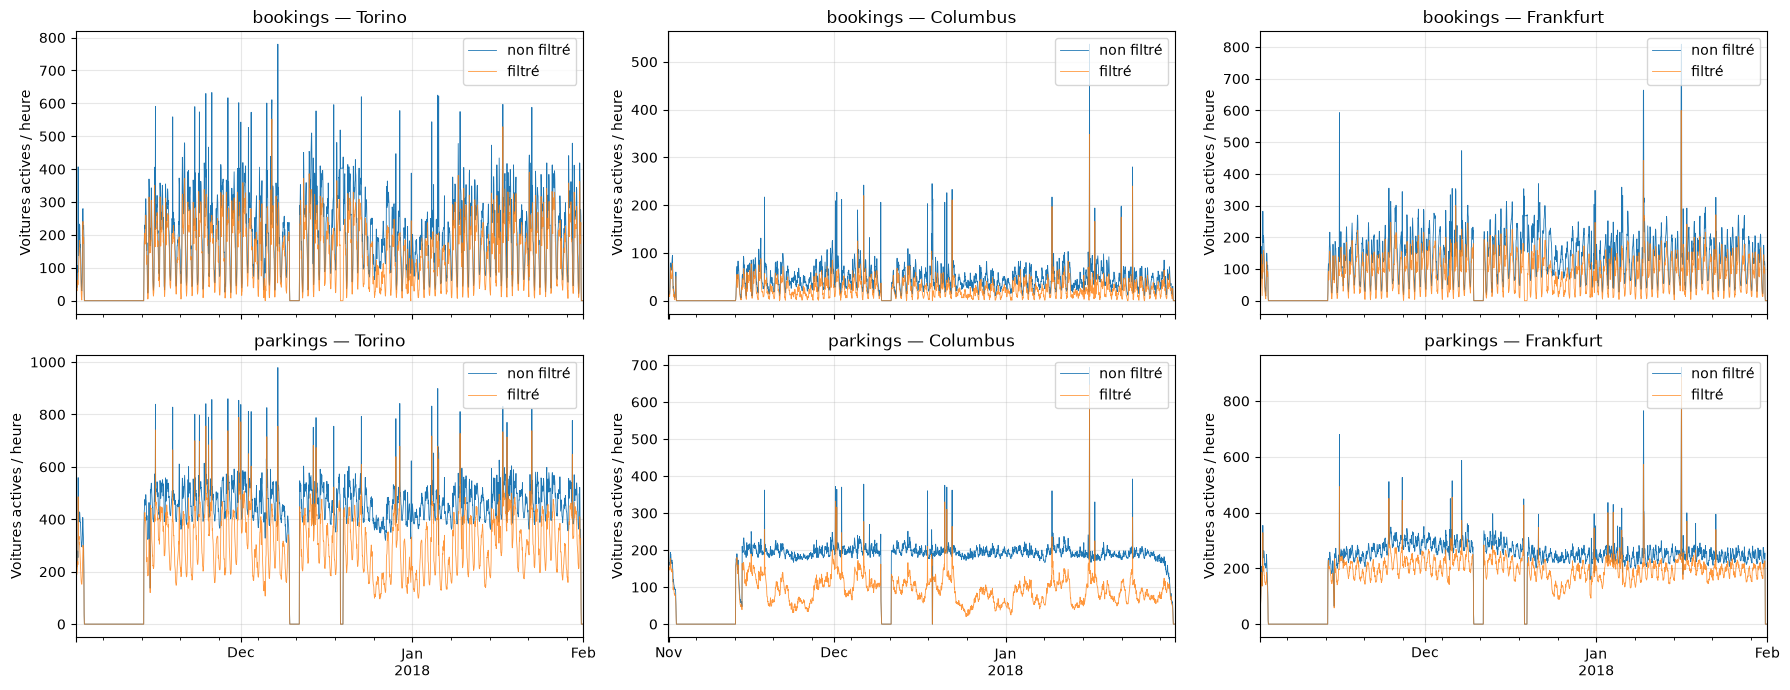

In [10]:
# Série temporelle heure par heure sur toute la période : non filtré vs filtré
fig, axes = plt.subplots(2, 3, figsize=(18, 7), sharex="col")
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        occ_raw[kind][c].tz_convert(TZ[c]).plot(ax=ax, lw=0.6, label="non filtré")
        occ_f[kind][c].tz_convert(TZ[c]).plot(ax=ax, lw=0.6, alpha=0.8, label="filtré")
        ax.set_title(f"{kind} — {c}")
        ax.set_ylabel("Voitures actives / heure")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

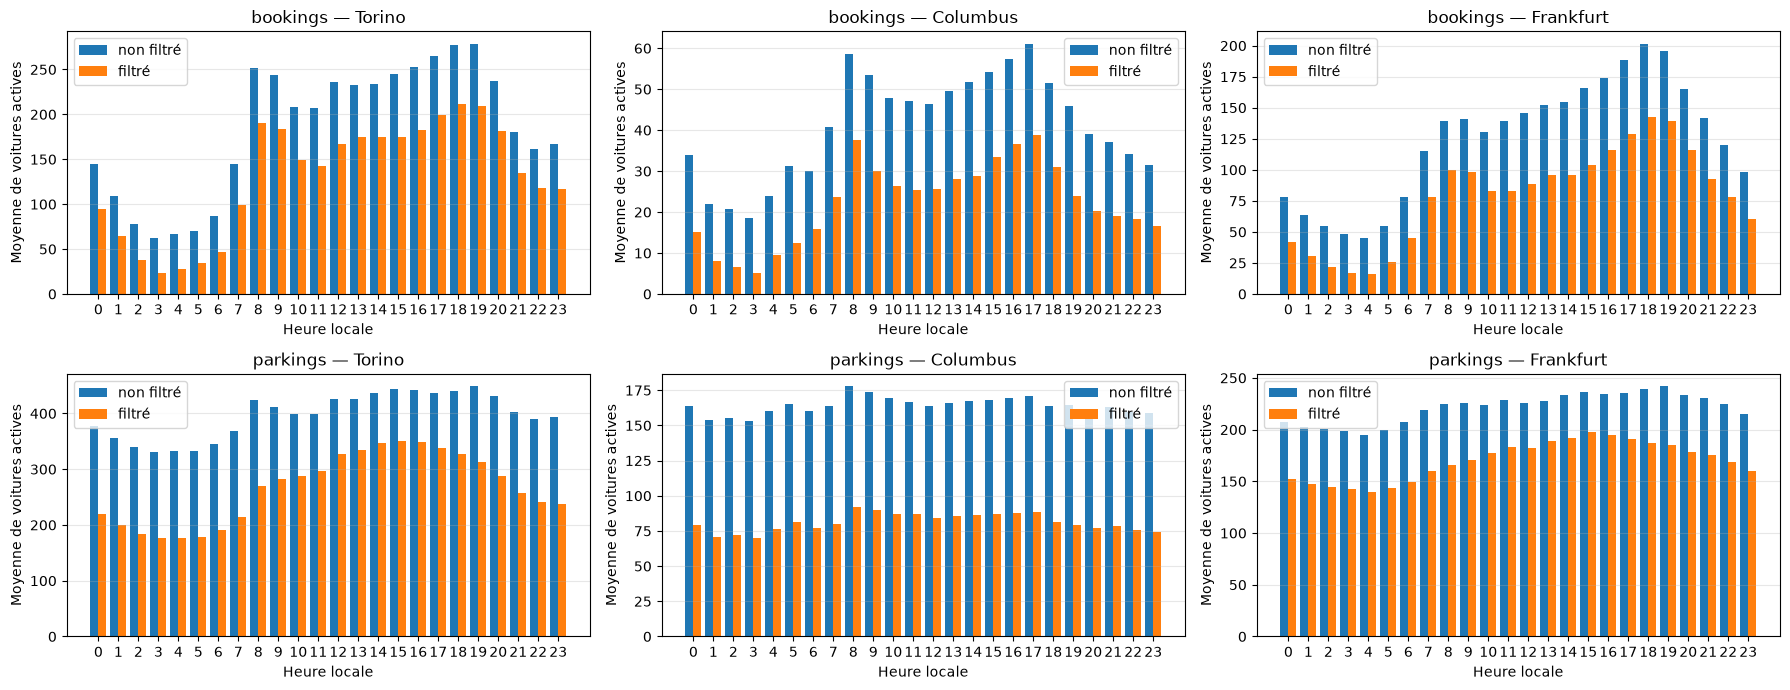

In [11]:
# Profil moyen par heure de la journée (heure locale) : non filtré vs filtré
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        p_raw = hour_of_day_profile(occ_raw[kind][c], c)
        p_f   = hour_of_day_profile(occ_f[kind][c], c)
        ax.bar(p_raw.index - 0.2, p_raw.values, width=0.4, label="non filtré")
        ax.bar(p_f.index + 0.2, p_f.values, width=0.4, label="filtré")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Heure locale")
        ax.set_ylabel("Moyenne de voitures actives")
        ax.set_xticks(range(24))
        ax.grid(axis="y", alpha=0.3)
        ax.legend()
plt.tight_layout(); plt.show()

In [12]:
# Part des événements retirés vs part de l'occupation retirée
# (un événement long compte dans beaucoup d'heures -> il pèse plus que 1 dans l'occupation)
rows = []
for kind in raw:
    for c in cities:
        n0, n1 = len(raw[kind][c]), len(filtered[kind][c])
        o0, o1 = occ_raw[kind][c].mean(), occ_f[kind][c].mean()
        rows.append({"type": kind, "ville": c,
                     "événements retirés": f"{1 - n1 / n0:.1%}",
                     "occupation moyenne brute": round(o0, 1),
                     "occupation moyenne filtrée": round(o1, 1),
                     "occupation retirée": f"{1 - o1 / o0:.1%}"})
pd.DataFrame(rows)

,type,ville,événements retirés,occupation moyenne brute,occupation moyenne filtrée,occupation retirée
0,bookings,Torino,18.2%,185.1,130.8,29.3%
1,bookings,Columbus,28.3%,41.1,22.3,45.7%
2,bookings,Frankfurt,16.8%,124.6,79.1,36.5%
3,parkings,Torino,17.7%,397.3,266.1,33.0%
4,parkings,Columbus,15.1%,164.2,81.1,50.6%
5,parkings,Frankfurt,16.9%,221.4,169.9,23.3%


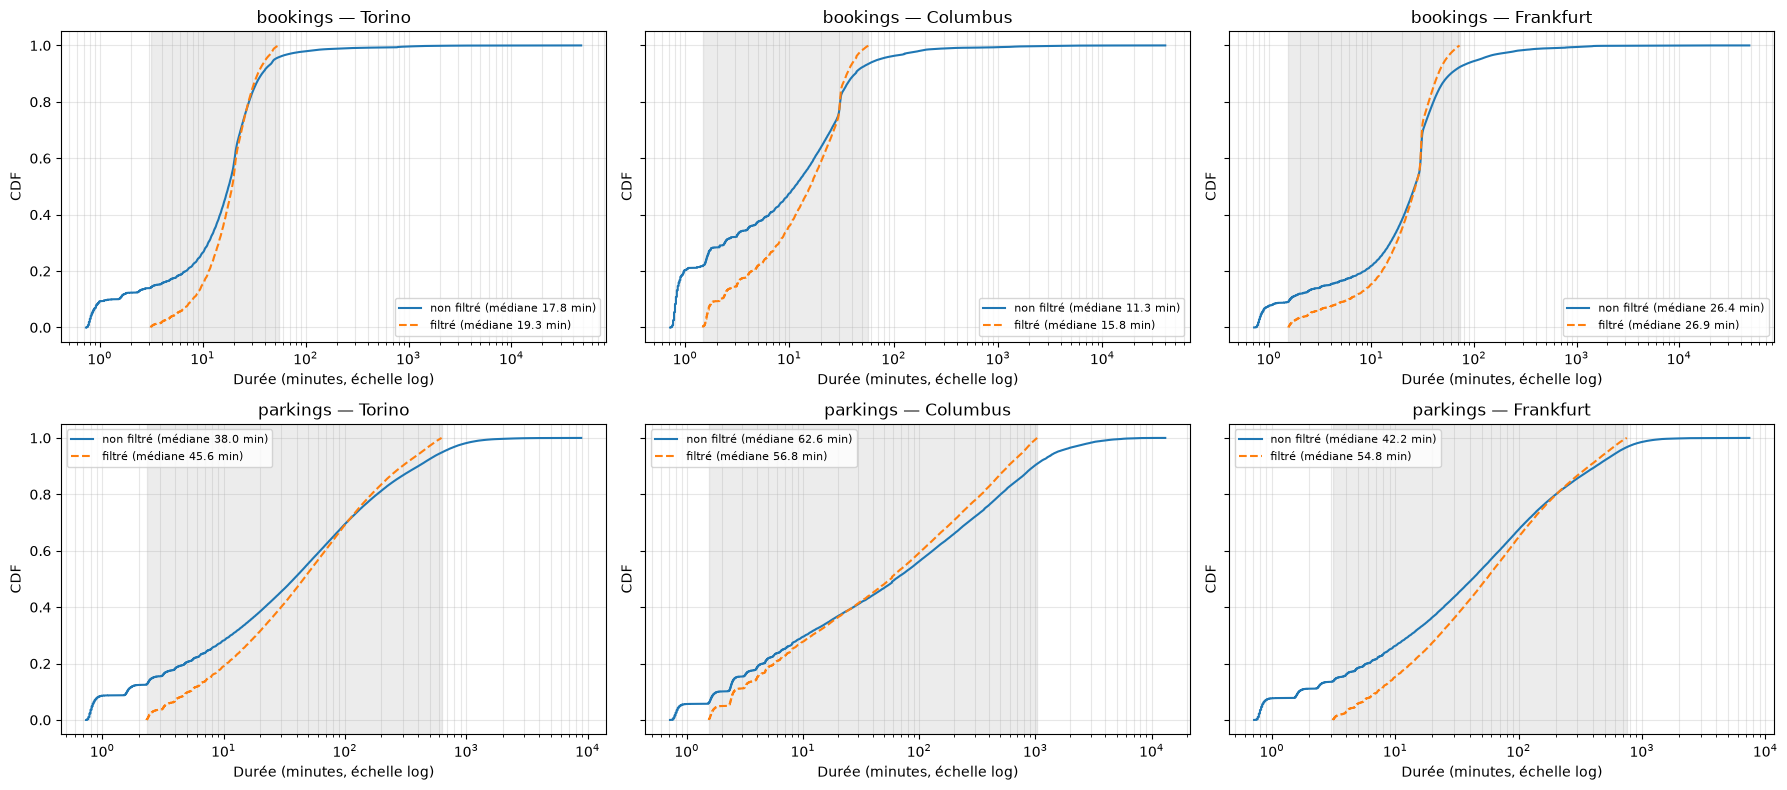

In [13]:
# CDF brute (trait plein) vs filtrée (pointillés), une figure par ville ; zone gardée en gris
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
for r, kind in enumerate(raw):
    for j, c in enumerate(cities):
        ax = axes[r, j]
        for df, style, lab in [(raw[kind][c], "-", "non filtré"), (filtered[kind][c], "--", "filtré")]:
            x = np.sort(df["duration_min"].to_numpy())
            x = x[x > 0]
            ax.plot(x, np.arange(1, len(x) + 1) / len(x), style,
                    label=f"{lab} (médiane {np.median(x):.1f} min)")
        ax.axvspan(*zones[(kind, c)], color="grey", alpha=0.15)
        ax.set_xscale("log")
        ax.set_title(f"{kind} — {c}")
        ax.set_xlabel("Durée (minutes, échelle log)")
        ax.set_ylabel("CDF")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Q6

In [14]:
bookings_fT = load_wtime("PermanentBookings", "Torino", True)
bookings_fT

,init_time,duration,day,week,iso_year,dow,hour,pt_duration,pt_distance,duration_min,pt_duration_min
0,1517396164,277,2018-01-31,5,2018,3,11,1059,2044,4.616667,17.650000
1,1517396050,767,2018-01-31,5,2018,3,11,1125,3174,12.783333,18.750000
2,1517395878,230,2018-01-31,5,2018,3,11,415,1089,3.833333,6.916667
3,1517395878,617,2018-01-31,5,2018,3,11,1429,3369,10.283333,23.816667
4,1517395878,888,2018-01-31,5,2018,3,11,1348,3253,14.800000,22.466667
...,...,...,...,...,...,...,...,...,...,...,...
63160,1509494572,891,2017-11-01,44,2017,3,1,2132,5367,14.850000,35.533333
63161,1509494455,2079,2017-11-01,44,2017,3,1,537,1709,34.650000,8.950000
63162,1509494455,574,2017-11-01,44,2017,3,1,1100,4270,9.566667,18.333333
63163,1509494455,1573,2017-11-01,44,2017,3,1,2936,7361,26.216667,48.933333


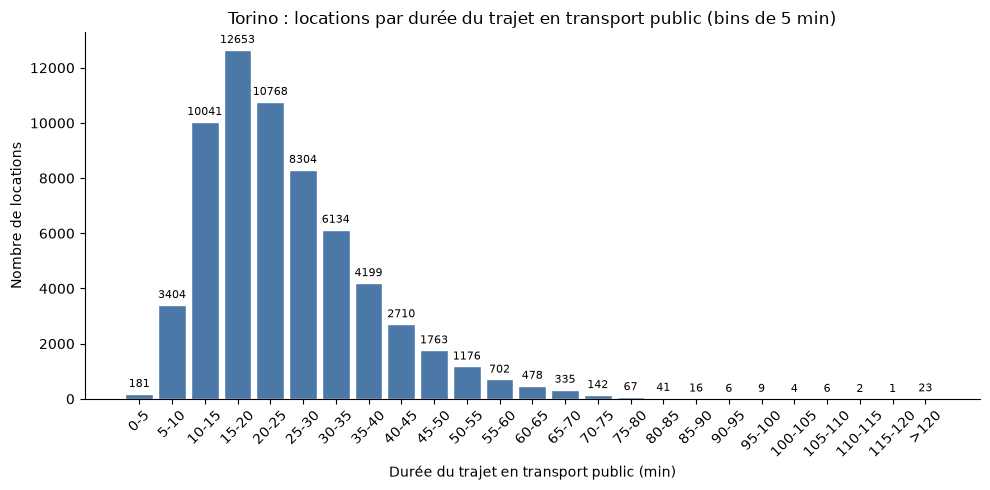

In [15]:
step = 5
cap = 120

edges = list(range(0, cap + step, step)) + [np.inf]
labels = [f"{a}-{a+step}" for a in range(0, cap, step)] + [f">{cap}"]
bookings_fT["pt_bin"] = pd.cut(bookings_fT["pt_duration_min"], bins=edges, labels=labels, right=False)

bookings_fT["pt_bin_start"] = pd.cut(bookings_fT["pt_duration_min"], bins=edges,
                            labels=edges[:-1], right=False).astype(float)
counts = bookings_fT["pt_bin"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index.astype(str), counts.values,
              color="#4C78A8", edgecolor="white", width=0.85)
ax.bar_label(bars, fmt="%d", padding=3, fontsize=8)

ax.set_title("Torino : locations par durée du trajet en transport public (bins de 5 min)")
ax.set_xlabel("Durée du trajet en transport public (min)")
ax.set_ylabel("Nombre de locations")
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


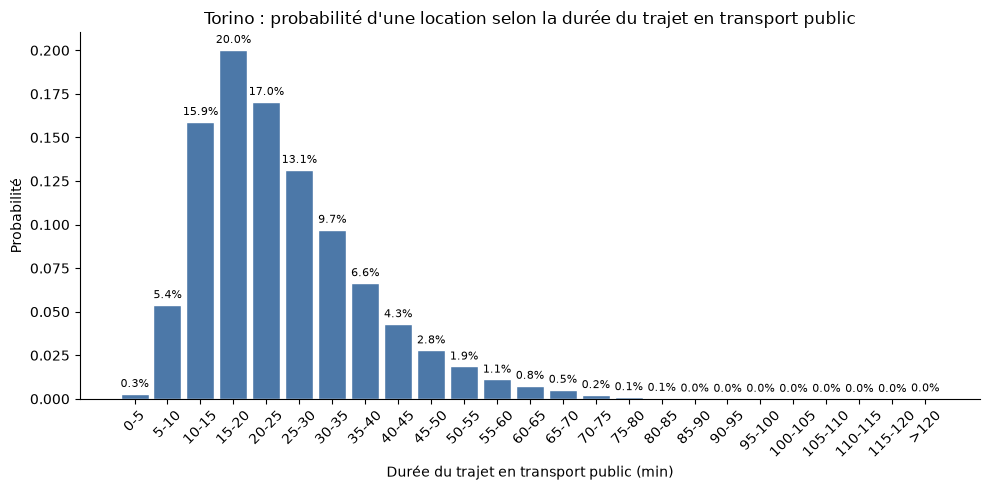

In [16]:
counts = bookings_fT["pt_bin"].value_counts().sort_index()
prob = counts / counts.sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(prob.index.astype(str), prob.values,
              color="#4C78A8", edgecolor="white", width=0.85)
ax.bar_label(bars, labels=[f"{p:.1%}" for p in prob.values], padding=3, fontsize=8)

ax.set_title("Torino : probabilité d'une location selon la durée du trajet en transport public")
ax.set_xlabel("Durée du trajet en transport public (min)")
ax.set_ylabel("Probabilité")
ax.tick_params(axis="x", rotation=45)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# b
We get the histogram of the number of booking in each bins of the duration of the public transportation duration divided by the total number of reservation during the period.

If A is public transport duration is in bin X
and B is we get a booking/rental 

than P(B|A) is seing a booking when the duration of PT is in the bin X 
We are observing P(B|A) and P(A)
And we can get the proba of observing a rental of a given duration 
